In [24]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

df = pd.read_csv('../01 - DataPreparation/df_prepared.csv')
print(df.columns)

Index(['BGGId', 'GameWeight', 'MinPlayers', 'MaxPlayers', 'NumOwned',
       'NumWant', 'NumAlternates', 'NumExpansions', 'NumImplementations',
       'IsReimplementation', 'Kickstarted', 'Cat:Thematic', 'Cat:Strategy',
       'Cat:War', 'Cat:Family', 'Cat:CGS', 'Cat:Abstract', 'Cat:Party',
       'Cat:Childrens', 'Rating', 'Age', 'AvgPlaytime', 'AgeRec',
       'NumOwned_log', 'NumAlternates_log', 'NumExpansions_log',
       'NumImplementations_log', 'NumWant_log', 'AvgPlaytime_log',
       'MaxPlayers_log'],
      dtype='object')


All features are kept, preferring log if available.

In [25]:
feature_columns = [ 'GameWeight', 'MinPlayers', 'MaxPlayers_log', 
       'IsReimplementation', 'Kickstarted', 'Cat:Thematic', 'Cat:Strategy',
       'Cat:War', 'Cat:Family', 'Cat:CGS', 'Cat:Abstract', 'Cat:Party',
       'Cat:Childrens',  'Age', 'AgeRec','NumOwned_log', 'NumAlternates_log', 
       'NumExpansions_log', 'NumImplementations_log', 'NumWant_log', 'AvgPlaytime_log']
X = df[feature_columns]
y = df['Rating']

In [26]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Original labels:", label_encoder.classes_)
print("Encoded mapping:", dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

Original labels: ['High' 'Low' 'Medium']
Encoded mapping: {'High': np.int64(0), 'Low': np.int64(1), 'Medium': np.int64(2)}


In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.3,
    random_state=42,
    stratify=y_encoded
)

In [28]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [29]:
knn = KNeighborsClassifier()
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)

y_test_decoded = label_encoder.inverse_transform(y_test)
y_pred_decoded = label_encoder.inverse_transform(y_pred)

print("Baseline KNN Accuracy:", round(accuracy_score(y_test, y_pred), 2))
print("\nConfusion Matrix:\n", confusion_matrix(y_test_decoded, y_pred_decoded, labels=label_encoder.classes_))
print("\nClassification Report:\n", classification_report(y_test_decoded, y_pred_decoded))


Baseline KNN Accuracy: 0.63

Confusion Matrix:
 [[ 867   63  504]
 [  55 1309  620]
 [ 400  633 1721]]

Classification Report:
               precision    recall  f1-score   support

        High       0.66      0.60      0.63      1434
         Low       0.65      0.66      0.66      1984
      Medium       0.60      0.62      0.61      2754

    accuracy                           0.63      6172
   macro avg       0.64      0.63      0.63      6172
weighted avg       0.63      0.63      0.63      6172



Baseline KNN gets 0.63 accuracy with fairly even performance across classes (macro F1 0.63). Biggest errors are High->Medium and Low->Medium, showing the model tends to predict Medium when uncertain.

We now run a 5-fold GridSearchCV to tune a KNeighborsClassifier over multiple hyperparameters optimizing for macro F1

In [30]:
param_grid = {
    'n_neighbors': [5, 10, 15, 20, 25, 30, 50],
    'weights': ['uniform'],
    'metric': ['euclidean', 'manhattan', 'minkowski'],
    'p': [1, 2],
    'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute']
}

knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

knn_grid.fit(X_train_scaled, y_train)

print("Best Parameters:", knn_grid.best_params_)
print("Best CV F1-Score:", round(knn_grid.best_score_, 3))

Best Parameters: {'algorithm': 'auto', 'metric': 'manhattan', 'n_neighbors': 20, 'p': 1, 'weights': 'uniform'}
Best CV F1-Score: 0.672


Best KNN setup uses 20 neighbors with Manhattan distance (p=1) and uniform weighting, yielding a macro-F1 of ~0.672 in CV, which is a modest improvement over the baseline and indicates slightly better balanced class performance.

In [31]:
best_knn = knn_grid.best_estimator_
y_pred_train = best_knn.predict(X_train_scaled)
y_pred_test = best_knn.predict(X_test_scaled)

train_acc = accuracy_score(y_train, y_pred_train)
test_acc = accuracy_score(y_test, y_pred_test)

print(f"Train accuracy: {train_acc:.3f}")

print(f"Test accuracy: {test_acc:.3f}\n")

# Decode for display
y_test_decoded = label_encoder.inverse_transform(y_test)
y_pred_test_decoded = label_encoder.inverse_transform(y_pred_test)

print("Confusion Matrix (Test Set):")
print(confusion_matrix(y_test_decoded, y_pred_test_decoded, labels=label_encoder.classes_))

print("\nClassification Report (Test Set):")
print(classification_report(y_test_decoded, y_pred_test_decoded))


Train accuracy: 0.710
Test accuracy: 0.670

Confusion Matrix (Test Set):
[[ 840   49  545]
 [  17 1386  581]
 [ 274  568 1912]]

Classification Report (Test Set):
              precision    recall  f1-score   support

        High       0.74      0.59      0.65      1434
         Low       0.69      0.70      0.70      1984
      Medium       0.63      0.69      0.66      2754

    accuracy                           0.67      6172
   macro avg       0.69      0.66      0.67      6172
weighted avg       0.68      0.67      0.67      6172



Tuned KNN shows mild overfitting (train 0.71 vs test 0.67) and achieves moderate test performance (macro-F1 ~0.67). Low is predicted best, while High is hardest (often misclassified as Medium); most remaining errors are Medium->Low and High->Medium.


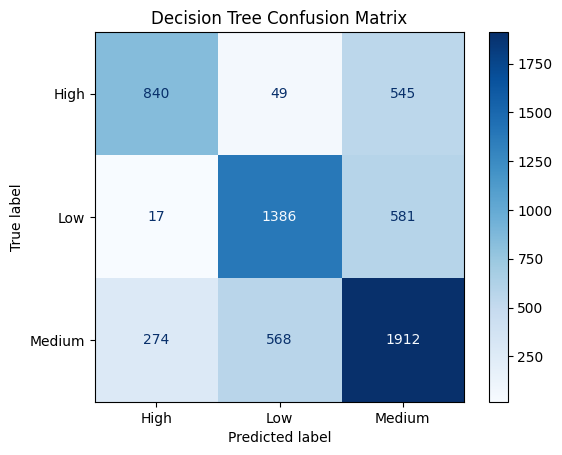

In [32]:
# Confusion matrix as a heatmap
cm = confusion_matrix(y_test, y_pred_test, labels=best_knn.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.inverse_transform(best_knn.classes_))
disp.plot(cmap=plt.cm.Blues)
plt.title("Decision Tree Confusion Matrix")
plt.show()


correct predictions are strongest on the diagonal, but the model often defaults to Medium. Medium is also sometimes predicted as Low, while direct High<->Low confusion is rare.


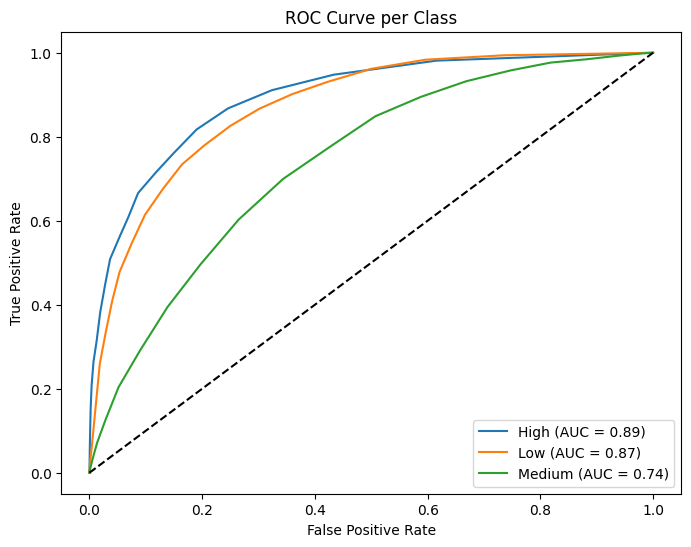

In [33]:
y_bin = label_binarize(y_test, classes=best_knn.classes_)
y_score = best_knn.predict_proba(X_test_scaled)

plt.figure(figsize=(8,6))
for i, class_label in enumerate(best_knn.classes_):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_score[:, i])
    plt.plot(fpr, tpr, label=f'{label_encoder.inverse_transform(best_knn.classes_)[i]} (AUC = {auc(fpr, tpr):.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve per Class")
plt.legend()
plt.show()


The ROC curve shows good separation for High (AUC=0.89) and Low (AUC=0.87), with Medium being the lowest (AUC=0.74). ALl curves are way above the random baseline